# Red de transferencias de tokens Ethereum

**Proyecto final — Estructura de Datos**
**Universidad Industrial de Santander**

**Profesor:** Jonnathan Alfredo Ramos Chaux
**Equipo:** Jhon Arciniegas, Pablo Álvarez y Emerson Ballesteros (líder)

[Abrir este notebook en Google Colab](https://colab.research.google.com/github/arcibyte/ethereum-exchange/blob/main/notebooks/Proyecto_Teoria_Grafos.ipynb)

---

## ¿De qué trata el proyecto?

Analizamos un **grafo** construido a partir de transferencias de un token
ERC-20 de Ethereum. Las direcciones son los **nodos** y las transferencias
son las **aristas** (dirigidas y con peso = cantidad transferida).

A partir de ese grafo resolvemos **4 tareas**, una por integrante:

| Tarea | Pregunta | Algoritmo | Responsable |
|-------|----------|-----------|-------------|
| 1 | ¿Cuál es el camino más barato entre dos direcciones? | Bellman-Ford | Pablo Álvarez |
| 2 | ¿Qué nodos son los más importantes? | Centralidad + PageRank | Jhon Arciniegas |
| 3 | ¿Qué grupos de nodos interactúan más entre sí? | Louvain (comunidades) | Emerson Ballesteros |
| 4 | ¿Cuál es la red mínima que conecta a todos? | Kruskal (MST) | Grupal |

**Reglas del proyecto:**
- No se permite usar el algoritmo de **Dijkstra**.
- Todo se implementa desde cero con Python (listas y diccionarios).

> **Cómo ejecutar:** en Colab, corre las celdas en orden. La celda de
> configuración clona el repositorio automáticamente. En local, abre el
> notebook desde `notebooks/` y la misma celda detecta la raíz.


## Configuración

Esta celda deja el entorno listo **tanto en Google Colab como en local**:

- En **Colab**, clona el repositorio desde GitHub y se ubica en su raíz.
- En **local**, detecta la raíz del repositorio automáticamente.

No necesitas cambiar rutas a mano: la celda lo hace por ti.


In [1]:
# ============ CONFIGURACIÓN DEL ENTORNO (Colab + local) ============
import os
import sys
import subprocess

REPO_URL = "https://github.com/arcibyte/ethereum-exchange"
REPO_DIR = "ethereum-exchange"
EN_COLAB = "google.colab" in sys.modules


def _raiz_del_repo():
    """Sube por las carpetas hasta encontrar la raíz (donde está src/grafo.py)."""
    actual = os.getcwd()
    while True:
        if os.path.isfile(os.path.join(actual, "src", "grafo.py")):
            return actual
        padre = os.path.dirname(actual)
        if padre == actual:
            return None
        actual = padre


if EN_COLAB:
    # Si ya estamos dentro del repo (por una ejecución anterior), no clonamos.
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            print("Clonando el repositorio...")
            subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_DIR)
else:
    raiz = _raiz_del_repo()
    if raiz is not None:
        os.chdir(raiz)

# La raíz del repo debe estar en sys.path para poder importar `src`.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print("Directorio de trabajo:", os.getcwd())


Directorio de trabajo: /home/arcibyte/proyecto


In [2]:
# Para graficar
import matplotlib.pyplot as plt

# Nuestros módulos (implementados desde cero)
from src.grafo import Grafo
from src.bellman_ford import bellman_ford, reconstruir_camino
from src.centralidad import centralidad_grado, pagerank, top_n
from src.comunidades import simetrizar, modularidad, louvain, resumen_comunidades
from src.arbol_expansion import UnionFind, aristas_no_dirigidas, kruskal, resumen_mst

# Rutas de los archivos de ejemplo (relativas a la raíz del repo)
RUTA_TRANSFERENCIAS = "data/sample/transferencias.csv"
RUTA_ETIQUETAS = "data/sample/etiquetas.csv"

# Para usar una muestra más grande generada con scripts/preparar_dataset.py:
# RUTA_TRANSFERENCIAS = "data/muestra/transferencias_100k.csv"

print("Todo listo.")


Todo listo.


## Sección 1 — El dataset

Usamos un archivo CSV con transferencias de tokens. Cada fila es una
transferencia de una dirección a otra:

| Columna | Significado |
|---------|-------------|
| `from_address` | dirección que envía |
| `to_address` | dirección que recibe |
| `value` | cantidad transferida |

Para este ejemplo usamos una **muestra pequeña** (12 direcciones y 24
transferencias) para que todo se entienda y corra rápido. La misma idea se
aplica al dataset completo (millones de filas).


Resumen del grafo:
  nodos: 12
  aristas: 20
  densidad: 0.1515


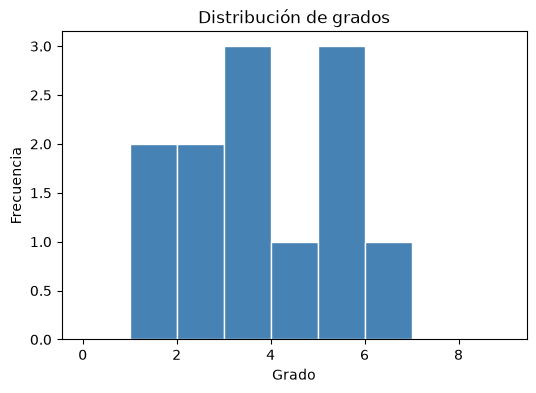

In [3]:
# Cargamos el grafo desde el CSV.
grafo = Grafo()
grafo.cargar_transferencias(RUTA_TRANSFERENCIAS)
grafo.cargar_etiquetas(RUTA_ETIQUETAS)

print("Resumen del grafo:")
resumen = grafo.resumen()
for clave, valor in resumen.items():
    print(f"  {clave}: {valor}")

# Grado (número de conexiones) de cada nodo.
grados = {}
for u, vecinos in grafo.adj.items():
    grados[u] = grados.get(u, 0) + len(vecinos)   # aristas de salida
    for v, _ in vecinos:
        grados[v] = grados.get(v, 0) + 1          # aristas de entrada

# Histograma de grados.
plt.figure(figsize=(6, 4))
plt.hist(list(grados.values()), bins=range(0, 10), color="steelblue", edgecolor="white")
plt.xlabel("Grado")
plt.ylabel("Frecuencia")
plt.title("Distribución de grados")
plt.show()


## Sección 2 — Análisis extenso del dataset completo

Aquí no usamos la muestra pequeña: trabajamos con el **Parquet completo**
(~38 millones de transferencias, ~2.3 GB) que genera
`notebooks/Preparar_Dataset_Colab.ipynb`.

Todo sale del **dataset real**:

1. **Estadísticas y distribuciones** del dataset completo.
2. **Estudio de escalabilidad**: extraemos subgrafos reales cada vez más
   grandes y medimos cuánto tarda cada algoritmo.

La meta es mostrar, con datos reales, por qué Bellman-Ford y Louvain se
ejecutan sobre un subgrafo y Kruskal/PageRank pueden correr a mayor escala.


### 2.0 Configuración

Cambia estos valores para agrandar o achicar el análisis.

In [4]:
# ============ CONFIGURACIÓN DEL ANÁLISIS EXTENSO ============
# Todo se calcula con el dataset real (el Parquet). No hay datos inventados.

# Ruta al Parquet completo (~2.3 GB).
# - Si acabas de correr Preparar_Dataset_Colab.ipynb en esta misma sesión:
RUTA_PARQUET = "/content/transferencias.parquet"
# - Si lo guardaste en Drive, descomenta estas dos líneas:
# from google.colab import drive
# drive.mount("/content/drive")
# RUTA_PARQUET = "/content/drive/MyDrive/ED2/transferencias.parquet"

# Cuántas filas usar en el análisis descriptivo (None = todas).
FILAS_ANALISIS = None

# Tamaños del benchmark (número de aristas reales extraídas del dataset).
# Súbelos si quieres un análisis más largo; bájalos si Colab va lento.
TAMANOS = [1_000, 5_000, 10_000, 25_000, 50_000, 100_000]

# Repeticiones por medición (se usa la mediana) y tiempo máximo por corrida.
REPETICIONES = 3
TIMEOUT_SEG = 30

# Opcional: analizar un solo token (dirección del contrato).
TOKEN = None

print("Configuración lista.")

Configuración lista.


### 2.1 Estadísticas y distribuciones del dataset completo

In [5]:
import os

if RUTA_PARQUET and os.path.isfile(RUTA_PARQUET):
    try:
        import duckdb  # noqa: F401
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb", "pyarrow"], check=True)

    from src.analisis import abrir, estadisticas

    con = abrir()
    datos = estadisticas(con, RUTA_PARQUET, filas=FILAS_ANALISIS, token=TOKEN)
    r = datos["resumen"]

    print(f"Transferencias analizadas : {r['transferencias']:,}")
    print(f"Direcciones origen        : {r['origenes']:,}")
    print(f"Direcciones destino       : {r['destinos']:,}")
    print(f"Volumen total             : {r['volumen']:,.2f}")
    print(f"Valor promedio            : {r['promedio']:,.4f}")
    print(f"Valor máximo              : {r['maximo']:,.2f}")

    # Distribución de montos en escala logarítmica.
    bins = [str(int(b)) for b, _ in datos["valores"]]
    conteos = [n for _, n in datos["valores"]]
    plt.figure(figsize=(7, 4))
    plt.bar(bins, conteos, color="steelblue")
    plt.xlabel("log10(valor)")
    plt.ylabel("Número de transferencias")
    plt.title("Distribución de montos (dataset completo)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Distribución de grados en escala log-log.
    gx = [g for g, _ in datos["grados"] if g > 0]
    gy = [n for g, n in datos["grados"] if g > 0]
    plt.figure(figsize=(7, 4))
    plt.loglog(gx, gy, "o-", markersize=3, color="darkorange")
    plt.xlabel("Grado (conexiones)")
    plt.ylabel("Número de direcciones")
    plt.title("Distribución de grados (log-log)")
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Actividad por día (si el dataset trae columna de tiempo).
    if datos["actividad"]:
        dias = [d for d, _ in datos["actividad"]]
        n_dias = [n for _, n in datos["actividad"]]
        plt.figure(figsize=(9, 4))
        plt.plot(dias, n_dias, color="seagreen")
        plt.xlabel("Día")
        plt.ylabel("Transferencias")
        plt.title("Actividad por día")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    # Top 10 direcciones por volumen.
    top = datos["top_volumen"][:10]
    etiquetas = [a[:10] + "..." for a, _ in top]
    valores = [v for _, v in top]
    plt.figure(figsize=(7, 4))
    plt.barh(etiquetas[::-1], valores[::-1], color="mediumpurple")
    plt.xlabel("Volumen total")
    plt.title("Top 10 direcciones por volumen")
    plt.tight_layout()
    plt.show()
else:
    print("Sección omitida: configura RUTA_PARQUET con la ruta del Parquet.")
    print("Genera el Parquet con notebooks/Preparar_Dataset_Colab.ipynb.")

Sección omitida: configura RUTA_PARQUET con la ruta del Parquet.
Genera el Parquet con notebooks/Preparar_Dataset_Colab.ipynb.


### 2.2 Estudio de escalabilidad (benchmark)

Extraemos subgrafos reales de tamaño creciente y medimos el tiempo de cada
algoritmo. Si uno se pasa de `TIMEOUT_SEG`, se marca como *timeout* y no se
vuelve a probar en tamaños mayores (su costo solo puede crecer).

In [6]:
import os

if RUTA_PARQUET and os.path.isfile(RUTA_PARQUET):
    from src.analisis import abrir, extraer_base, benchmark

    con = abrir()
    base = extraer_base(con, RUTA_PARQUET, max(TAMANOS), token=TOKEN)
    resultados = benchmark(base, TAMANOS, repeticiones=REPETICIONES, timeout=TIMEOUT_SEG)

    print(f"\n{'Algoritmo':<14} {'Aristas':>10} {'Nodos':>8} {'Tiempo (s)':>12}")
    for fila in resultados:
        t = "timeout" if fila["tiempo"] is None else f"{fila['tiempo']:.4f}"
        print(f"{fila['algoritmo']:<14} {fila['aristas']:>10,} {fila['nodos']:>8,} {t:>12}")

    plt.figure(figsize=(8, 5))
    for nombre in ["Kruskal", "PageRank", "Bellman-Ford", "Louvain"]:
        puntos = [(f["aristas"], f["tiempo"]) for f in resultados
                  if f["algoritmo"] == nombre and f["tiempo"] is not None]
        if puntos:
            plt.loglog([p[0] for p in puntos], [p[1] for p in puntos], "o-", label=nombre)
    plt.xlabel("Aristas del subgrafo real")
    plt.ylabel("Tiempo (segundos)")
    plt.title("Escalabilidad de los algoritmos (datos reales)")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Sección omitida: configura RUTA_PARQUET con la ruta del Parquet.")

Sección omitida: configura RUTA_PARQUET con la ruta del Parquet.


### 2.3 Cómo leer estos resultados

- **Kruskal** y **PageRank** crecen suave: aguantan subgrafos grandes.
- **Bellman-Ford** y **Louvain** se disparan: por eso se ejecutan sobre un
  subgrafo de miles de aristas.
- Los puntos que no aparecen en la gráfica se pasaron del `TIMEOUT_SEG`.

Esta comparación es la misma lección del burbuja vs. ordenamiento eficiente,
pero con algoritmos de grafos y sobre datos reales.


## Tarea 1 — Caminos de costo mínimo (Bellman-Ford)

**Responsable:** Pablo Álvarez

**Problema:** queremos saber cuál es la ruta más barata (menor cantidad
transferida) para ir de una dirección a otra.

**Equivalencia matemática:** camino de costo mínimo en un grafo dirigido y
ponderado. El costo de un camino es la suma de los pesos de sus aristas.

**Alternativas consideradas:**

| Algoritmo | ¿Por qué sí / no? |
|-----------|-------------------|
| Dijkstra | Prohibido por las reglas del proyecto |
| BFS | Solo sirve cuando todas las aristas pesan lo mismo |
| **Bellman-Ford** | Funciona con pesos reales y detecta ciclos negativos |

**Elegimos Bellman-Ford.** Su complejidad es $O(|V| \cdot |E|)$, aceptable
para grafos de tamaño moderado.


In [7]:
# Elegimos un origen con nombre conocido para que el resultado sea legible.
origen = "0x1111"   # Uniswap
distancias, previos = bellman_ford(grafo.adj, origen)

print(f"Caminos más baratos desde {grafo.nombre(origen)}:")
for destino in sorted(grafo.nodos):
    d = distancias[destino]
    if d == float("inf"):
        print(f"  {grafo.nombre(destino):<12} : inalcanzable")
    else:
        camino = reconstruir_camino(previos, origen, destino)
        nombres = " -> ".join(grafo.nombre(n) for n in camino)
        print(f"  {grafo.nombre(destino):<12} : costo {d:>7.1f}   ({nombres})")


Caminos más baratos desde Uniswap:
  Uniswap      : costo     0.0   (Uniswap)
  Curve        : costo   150.0   (Uniswap -> Curve)
  Aave         : costo   270.0   (Uniswap -> Curve -> Aave)
  Binance      : costo   135.0   (Uniswap -> USDC -> Binance)
  Coinbase     : costo   335.0   (Uniswap -> USDC -> Binance -> Coinbase)
  USDC         : costo   130.0   (Uniswap -> USDC)
  DAI          : costo   265.0   (Uniswap -> USDC -> Binance -> DAI)
  cartera_a    : costo    90.0   (Uniswap -> cartera_a)
  cartera_b    : inalcanzable
  cartera_c    : costo   350.0   (Uniswap -> Curve -> Aave -> cartera_c)
  cartera_d    : costo   415.0   (Uniswap -> USDC -> Binance -> cartera_d)
  cartera_e    : inalcanzable


## Tarea 2 — Centralidad e influencia

**Responsable:** Jhon Arciniegas

**Problema:** ¿cuáles son los nodos más importantes de la red?

**Equivalencia matemática:** dos medidas de centralidad:

- **Grado:** $C(v) = \text{grado}(v) / (|V| - 1)$
- **PageRank:** $PR(v) = \frac{1-d}{N} + d \sum_{u \to v} \frac{PR(u)}{\text{grado_salida}(u)}$

**Alternativas:** la centralidad de cercanía y la de intermediación también
miden importancia, pero requieren calcular caminos mínimos repetidamente. Para
un primer análisis bastan el grado y PageRank.


In [8]:
# Centralidad de grado.
cent_grado = centralidad_grado(grafo.adj, grafo.nodos)

print("Top por centralidad de grado:")
for addr, score, nombre in top_n(cent_grado, n=5, etiquetas=grafo.etiquetas):
    print(f"  {nombre:<12} : {score:.3f}")

# PageRank.
pr = pagerank(grafo.adj, grafo.nodos)
print("\nTop por PageRank:")
for addr, score, nombre in top_n(pr, n=5, etiquetas=grafo.etiquetas):
    print(f"  {nombre:<12} : {score:.3f}")


Top por centralidad de grado:
  Binance      : 0.545
  Curve        : 0.455
  Coinbase     : 0.455
  Uniswap      : 0.455
  cartera_a    : 0.364

Top por PageRank:
  Binance      : 0.191
  Coinbase     : 0.162
  Curve        : 0.131
  Aave         : 0.124
  cartera_a    : 0.082


In [ ]:
# Gráfica — Top 5 por PageRank.
top_pr = top_n(pr, n=5, etiquetas=grafo.etiquetas)
nombres_pr = [nombre for _, _, nombre in top_pr]
scores_pr  = [score  for _, score, _ in top_pr]

plt.figure(figsize=(7, 4))
plt.barh(nombres_pr[::-1], scores_pr[::-1], color="steelblue")
plt.xlabel("PageRank")
plt.title("Top 5 direcciones por PageRank")
plt.tight_layout()
plt.show()


## Tarea 3 — Detección de comunidades (Louvain)

**Responsable:** Emerson Ballesteros (líder)

**Problema:** ¿qué grupos de direcciones interactúan mucho entre sí?
En Ethereum los exchanges y los DEX forman "ecosistemas": se relacionan mucho
entre ellos y poco con el resto.

**Equivalencia matemática:** maximizar la **modularidad** $Q$. Una partición
es buena si hay más aristas *dentro* de los grupos de las que habría en un
grafo aleatorio:

$$Q = \frac{1}{2m}\sum_{i,j}\left[A_{ij} - \frac{k_i k_j}{2m}\right]\delta(c_i, c_j)$$

- $A_{ij}$: peso de la arista entre $i$ y $j$.
- $k_i$: grado del nodo $i$.
- $m$: suma total de pesos.
- $\delta(c_i,c_j)$: 1 si $i$ y $j$ están en el mismo grupo, 0 si no.

Valores de $Q > 0.3$ indican una buena estructura de comunidades.

**Alternativas consideradas:**

| Algoritmo | ¿Por qué sí / no? |
|-----------|-------------------|
| Girvan-Newman | Muy lento para grafos grandes ($O(V \cdot E^2)$) |
| Clustering espectral | Necesita álgebra lineal densa |
| Propagación de etiquetas | Rápido pero inestable |
| **Louvain** | Rápido y da buenos resultados |

**Elegimos Louvain**, que se resume en dos pasos:

1. Cada nodo empieza en su propia comunidad.
2. Repetimos: mover cada nodo a la comunidad vecina que más aumente $Q$,
   hasta que ya nada mejore.

Modularidad Q = 0.696
Número de comunidades = 2

Comunidad 1: Aave, Curve, USDC, Uniswap, cartera_a, cartera_b, cartera_c
Comunidad 2: Binance, Coinbase, DAI, cartera_d, cartera_e


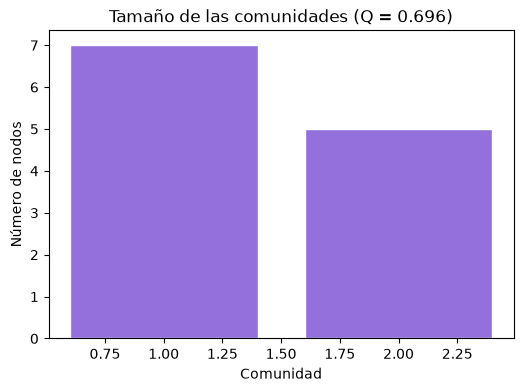

In [9]:
# Las comunidades se buscan sobre el grafo NO dirigido (simetrizado).
adj_no_dirigido = simetrizar(grafo.adj)

comunidades = louvain(adj_no_dirigido)
Q = modularidad(adj_no_dirigido, comunidades)

print(f"Modularidad Q = {Q:.3f}")
print(f"Número de comunidades = {len(set(comunidades.values()))}\n")

grupos = resumen_comunidades(comunidades, grafo.etiquetas)
for i, (c, nombres) in enumerate(sorted(grupos.items()), 1):
    print(f"Comunidad {i}: {', '.join(sorted(nombres))}")

# Tamaño de cada comunidad.
tamanos = [len(nombres) for nombres in grupos.values()]
plt.figure(figsize=(6, 4))
plt.bar(range(1, len(tamanos) + 1), tamanos, color="mediumpurple", edgecolor="white")
plt.xlabel("Comunidad")
plt.ylabel("Número de nodos")
plt.title(f"Tamaño de las comunidades (Q = {Q:.3f})")
plt.show()

## Tarea 4 — Árbol de expansión mínima (MST)

**Responsabilidad:** grupal

**Problema:** ¿cuál es el conjunto mínimo de conexiones que mantiene a toda
la red conectada?

**Equivalencia matemática:** árbol de expansión mínima. Es un árbol (sin
ciclos) que toca todos los nodos con el menor costo total.

**Alternativas consideradas:**

| Algoritmo | ¿Por qué sí / no? |
|-----------|-------------------|
| Prim | Necesita una cola de prioridad |
| **Kruskal** | Ordena aristas y usa Union-Find |

**Elegimos Kruskal** porque Union-Find es una estructura de datos clásica que
vale la pena estudiar.


In [10]:
# Convertimos las aristas dirigidas en no dirigidas.
aristas_nd = aristas_no_dirigidas(grafo.aristas)

mst, costo = kruskal(grafo.nodos, aristas_nd)
print(f"MST: {len(mst)} aristas, costo total = {costo:.1f}\n")

print("Aristas del árbol de expansión mínima:")
for a, b, w in sorted(mst, key=lambda e: e[2]):
    print(f"  {grafo.nombre(a):<12} -- {grafo.nombre(b):<12}  (peso {w:.1f})")


MST: 11 aristas, costo total = 1295.0

Aristas del árbol de expansión mínima:
  Binance      -- USDC          (peso 5.0)
  Aave         -- cartera_a     (peso 50.0)
  Curve        -- cartera_a     (peso 60.0)
  Curve        -- cartera_c     (peso 70.0)
  Curve        -- USDC          (peso 110.0)
  Coinbase     -- DAI           (peso 110.0)
  Uniswap      -- USDC          (peso 130.0)
  Binance      -- DAI           (peso 130.0)
  Coinbase     -- cartera_d     (peso 180.0)
  Uniswap      -- cartera_b     (peso 200.0)
  Coinbase     -- cartera_e     (peso 250.0)


## Conclusiones

**Responsable:** Emerson Ballesteros

A partir del análisis de la red de transferencias de tokens podemos concluir:

1. **Un mismo dataset admite varias preguntas.** No hay un único algoritmo
   "correcto": Bellman-Ford responde caminos, PageRank responde importancia,
   Louvain responde grupos y Kruskal responde conectividad mínima.

2. **Las estructuras de datos importan.** La lista de adyacencia recorre el
   grafo, Union-Find detecta ciclos en Kruskal, y los diccionarios y conjuntos
   hacen que todo sea simple y legible en Python.

3. **La red no es un solo bloque.** Louvain encontró dos comunidades claras
   (el ecosistema DEX y el de los exchanges), separadas por un puente débil.

4. **Sin Dijkstra también se puede.** Usamos Bellman-Ford y Kruskal, que se
   entienden con las estructuras de datos de tercer semestre.

En resumen, lo valioso no fue memorizar algoritmos, sino entender **qué
estructura de datos usa cada uno y por qué funciona**.